# Visualisatie & Storytelling – Eindopdracht deel 1

**Student 1:** [Hasnain Ali Hanif]  
**Student 2:** [Daim Hussain]

**Doel:** Ontwikkelingen in bosgebied en temperatuur inzichtelijk maken voor beleidsmakers van de Verenigde Naties.

*De bestaande Python-code is ongewijzigd behouden.*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Dataset inladen
df = pd.read_csv("forest_area_cleaned.csv")

# Eerste 5 rijen bekijken
df.head()

,area_name,area_code,year,forest_area
0,Afghanistan,AFG,1990,12084.4
1,Albania,ALB,1990,7888.0
2,Algeria,DZA,1990,16670.0
3,American Samoa,ASM,1990,180.7
4,Andorra,AND,1990,160.0


## Opdracht A – Wereldwijd bosgebied (1990–2020)

In [3]:
# Alleen de wereld selecteren
wereld = df[df["area_name"] == "World"].copy()

# Alleen 1990 tot en met 2020
wereld = wereld[
    (wereld["year"] >= 1990) &
    (wereld["year"] <= 2020)
]

# Ontbrekende waarden verwijderen
wereld = wereld.dropna(subset=["forest_area"])

# Sorteren op jaar
wereld = wereld.sort_values("year")

wereld.head()


,area_name,area_code,year,forest_area
797,World,WLD,1992,4.203424e+07
1063,World,WLD,1993,4.200109e+07
1329,World,WLD,1994,4.192261e+07
1595,World,WLD,1995,4.184413e+07
1861,World,WLD,1996,4.176565e+07


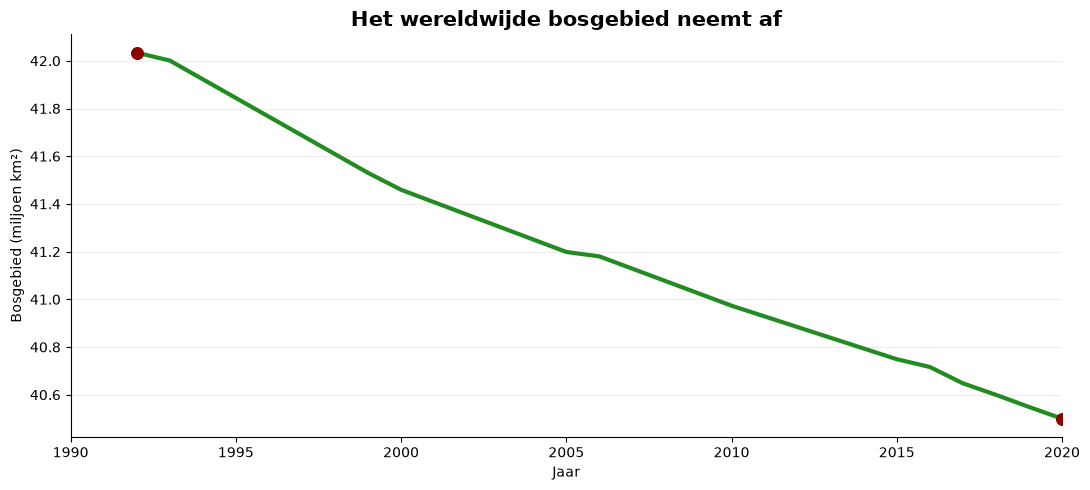

In [4]:
# Grafiek maken
plt.figure(figsize=(11, 5))

# Wereldwijd bosgebied tekenen
plt.plot(
    wereld["year"],
    wereld["forest_area"] / 1000000,
    color="forestgreen",
    linewidth=3
)

# Beginpunt en eindpunt benadrukken
plt.scatter(
    [wereld["year"].iloc[0], wereld["year"].iloc[-1]],
    [wereld["forest_area"].iloc[0] / 1000000,
     wereld["forest_area"].iloc[-1] / 1000000],
    color="darkred",
    s=70,
    zorder=3
)

# Titel en assen
plt.title(
    "Het wereldwijde bosgebied neemt af",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Jaar")
plt.ylabel("Bosgebied (miljoen km²)")

# Alleen lichte horizontale rasterlijnen
plt.grid(axis="y", alpha=0.2)

# Onnodige randen verwijderen
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.xlim(1990, 2020)

plt.tight_layout()
plt.show()


Voor deze opdracht heb ik een lijngrafiek gemaakt die de ontwikkeling van het wereldwijde bosgebied laat zien. De beschikbare gegevens tonen een afname van het bosgebied.

**Grafiekkeuze:** Ik heb een lijngrafiek gekozen omdat deze geschikt is om veranderingen over een langere periode te laten zien. Hierdoor kunnen VN-leiders de ontwikkeling van het wereldwijde bosgebied volgen en zien of de afname doorzet.

**Context:** De afname van bosgebied is belangrijk voor klimaatbeleid en biodiversiteit. Bossen slaan CO₂ op en bieden leefgebieden aan veel planten- en diersoorten. De grafiek kan VN-leiders helpen om het belang van bosbescherming te beoordelen.

**Clutter:** Ik heb de bovenste en rechterrand verwijderd, omdat deze geen extra informatie geven. Ook heb ik alleen lichte horizontale rasterlijnen gebruikt. Het bosgebied is weergegeven in miljoenen km², zodat de getallen gemakkelijker leesbaar zijn.

**Preattentive attributes:** De groene lijn laat de ontwikkeling van het bosgebied zien. Met rode punten worden het begin en het einde van de beschikbare periode benadrukt. Het kleurcontrast en de dikkere lijn helpen om de aandacht op de belangrijkste ontwikkeling te richten.

**Ontbrekende gegevens:** De waarden voor 1990 en 1991 ontbreken in de dataset. Daarom begint de lijn in 1992. Deze ontbrekende waarden zijn niet zelf ingevuld.

## Opdracht B – Bosgebied per inkomensniveau (1990–2020)

In [5]:
# De vijf inkomensgroepen
groepen = [
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

# Alleen deze groepen selecteren
inkomen = df[df["area_name"].isin(groepen)].copy()

# Alleen 1990 tot en met 2020
inkomen = inkomen[
    (inkomen["year"] >= 1990) &
    (inkomen["year"] <= 2020)
]

# Ontbrekende waarden verwijderen
inkomen = inkomen.dropna(subset=["forest_area"])

# Bekijken welke groepen gevonden zijn
print(inkomen["area_name"].unique())

inkomen.head()

<StringArray>
[        'High income',          'Low income', 'Lower middle income',
       'Middle income', 'Upper middle income']
Length: 5, dtype: str


,area_name,area_code,year,forest_area
233,High income,HIC,1990,1.011042e+07
245,Low income,LIC,1990,3.523832e+06
246,Lower middle income,LMC,1990,6.237384e+06
499,High income,HIC,1991,1.011727e+07
511,Low income,LIC,1991,3.507105e+06


groepen bevat de vijf inkomensgroepen.
isin(groepen) zoekt de rijen die bij deze groepen horen.
inkomen slaat de geselecteerde gegevens op.
head() laat de eerste vijf rijen zien.

In [6]:
# Bekijken welke inkomensgroepen gevonden zijn
print(inkomen["area_name"].unique())

<StringArray>
[        'High income',          'Low income', 'Lower middle income',
       'Middle income', 'Upper middle income']
Length: 5, dtype: str


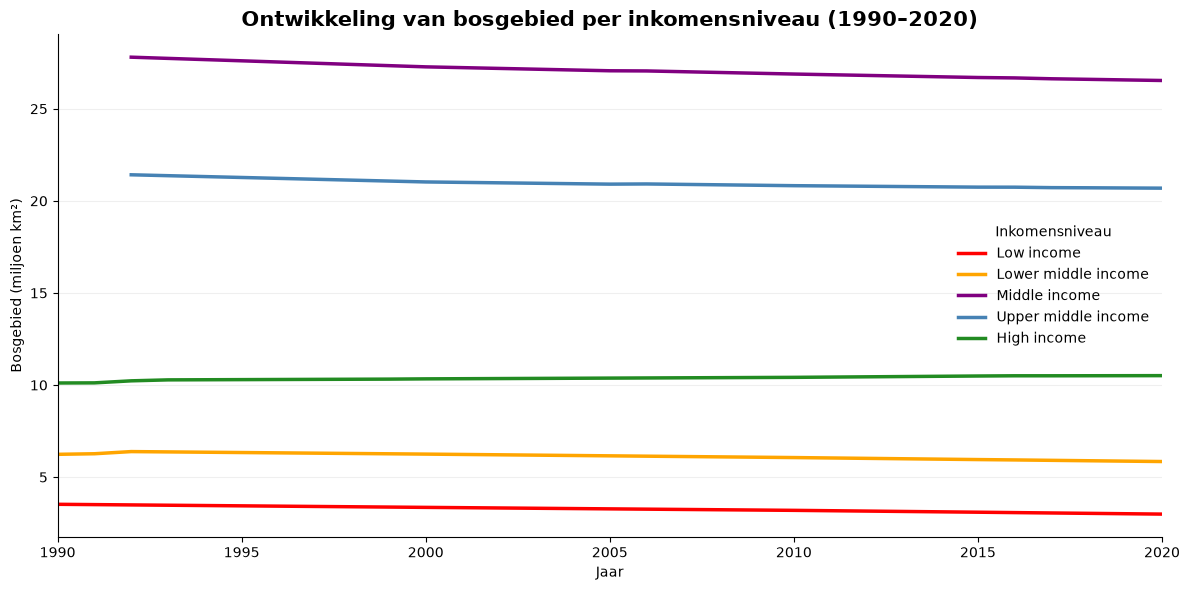

In [7]:
# Grafiek maken
plt.figure(figsize=(12, 6))

# Kleuren voor de inkomensgroepen
kleuren = [
    "red",
    "orange",
    "purple",
    "steelblue",
    "forestgreen"
]

# Grafiek maken voor de vijf inkomensgroepen
for groep, kleur in zip(groepen, kleuren):

    data = inkomen[inkomen["area_name"] == groep]
    data = data.sort_values("year")

    plt.plot(
        data["year"],
        data["forest_area"] / 1000000,
        label=groep,
        color=kleur,
        linewidth=2.5
    )

# Titel en assen
plt.title(
    "Ontwikkeling van bosgebied per inkomensniveau (1990–2020)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Jaar")
plt.ylabel("Bosgebied (miljoen km²)")

# Legenda
plt.legend(
    title="Inkomensniveau",
    frameon=False
)

# Lichte rasterlijnen
plt.grid(axis="y", alpha=0.2)

# Onnodige randen verwijderen
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.xlim(1990, 2020)

plt.tight_layout()
plt.show()

Voor deze opdracht heb ik een lijngrafiek gemaakt waarin vijf inkomensgroepen worden vergeleken. De grafiek laat zien hoe het bosgebied zich tussen 1990 en 2020 per inkomensgroep heeft ontwikkeld.

**Grafiekkeuze:** Ik heb gekozen voor een lijngrafiek met vijf lijnen omdat deze geschikt is om ontwikkelingen over meerdere jaren te vergelijken. Hierdoor kunnen VN-leiders zien hoe de bosoppervlakte per inkomensgroep verandert.

**Context:** De ontwikkeling van het bosgebied verschilt per inkomensgroep. Deze verschillen zijn relevant voor internationale klimaatmaatregelen, omdat landen met verschillende inkomensniveaus mogelijk andere middelen en ondersteuning nodig hebben voor bosbescherming.

**Clutter:** Ik heb de bovenste en rechterrand verwijderd en alleen lichte horizontale rasterlijnen gebruikt. Ook heb ik de waarden weergegeven in miljoenen km², zodat grote getallen gemakkelijker leesbaar zijn.

**Preattentive attributes:** Ik heb vijf verschillende kleuren gebruikt om de inkomensgroepen te onderscheiden. De lijnen hebben dezelfde dikte, zodat de groepen visueel gelijkwaardig worden behandeld. De richting en positie van de lijnen maken verschillen in ontwikkeling zichtbaar.

**Ontbrekende gegevens:** Sommige waarden ontbreken in de dataset. Deze zijn niet zelf ingevuld. De categorie Middle income overlapt bovendien met Lower middle income en Upper middle income. De vijf groepen kunnen daarom niet allemaal bij elkaar worden opgeteld.

## Opdracht C – Bosgebied vergelijken (2018–2020)

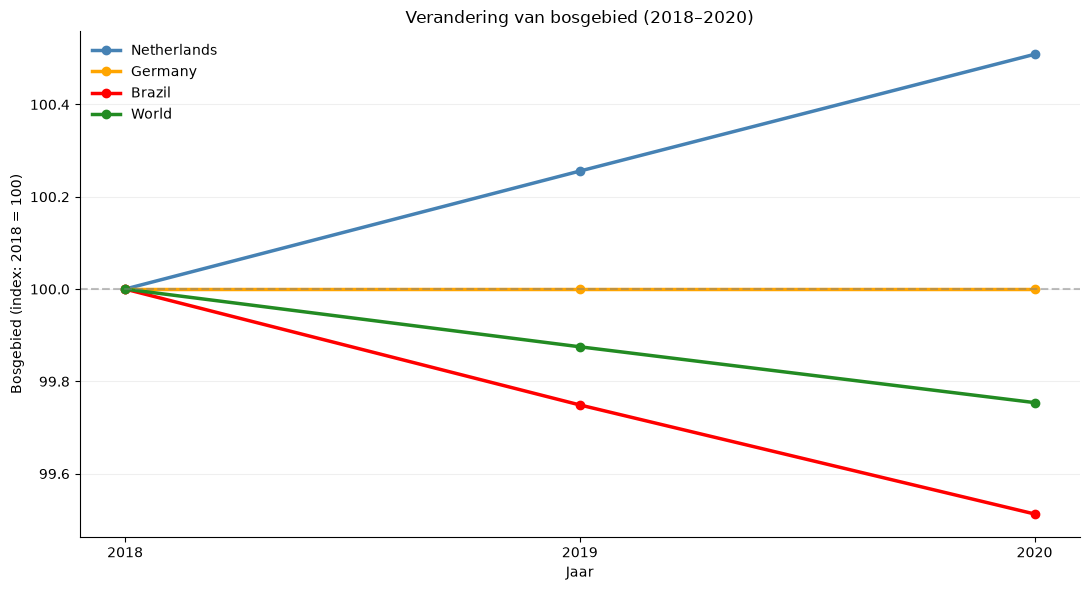

In [8]:
# Landen selecteren
landen = ["Netherlands", "Germany", "Brazil", "World"]

vergelijking = df[
    (df["area_name"].isin(landen)) &
    (df["year"].between(2018, 2020))
].copy()

# Ontbrekende waarden verwijderen
vergelijking = vergelijking.dropna(subset=["forest_area"])

# Bosgebied van 2018 als basis nemen
basis = vergelijking[vergelijking["year"] == 2018]
basis = basis.set_index("area_name")["forest_area"]

# Index berekenen
vergelijking["index"] = vergelijking.apply(
    lambda rij: rij["forest_area"] / basis[rij["area_name"]] * 100,
    axis=1
)

# Grafiek maken
plt.figure(figsize=(11, 6))

kleuren = {
    "Netherlands": "steelblue",
    "Germany": "orange",
    "Brazil": "red",
    "World": "forestgreen"
}

for land in landen:
    data = vergelijking[vergelijking["area_name"] == land]
    data = data.sort_values("year")

    plt.plot(
        data["year"],
        data["index"],
        marker="o",
        linewidth=2.5,
        color=kleuren[land],
        label=land
    )

plt.axhline(100, color="gray", linestyle="--", alpha=0.5)

plt.title("Verandering van bosgebied (2018–2020)")
plt.xlabel("Jaar")
plt.ylabel("Bosgebied (index: 2018 = 100)")

plt.xticks([2018, 2019, 2020])
plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.2)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Omdat de wereld veel meer bosgebied heeft dan Nederland, gebruiken we vier kleine lijngrafieken naast elkaar in één figuur. Zo kun je de ontwikkeling van 2018 tot 2020 per gebied goed bekijken.

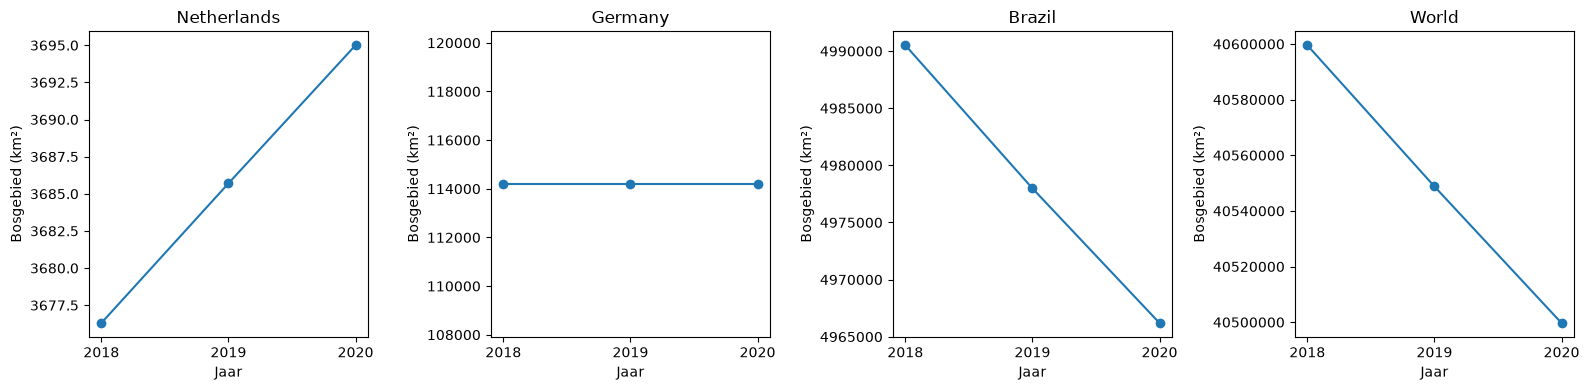

In [9]:
# Vier grafieken maken
fig, assen = plt.subplots(1, 4, figsize=(16, 4))

# Voor ieder land een grafiek
for i, land in enumerate(landen):
    data = vergelijking[vergelijking["area_name"] == land]

    assen[i].plot(data["year"], data["forest_area"], marker="o")
    assen[i].set_title(land)
    assen[i].set_xlabel("Jaar")
    assen[i].set_ylabel("Bosgebied (km²)")
    assen[i].set_xticks([2018, 2019, 2020])
    assen[i].ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

| Code | Betekenis |
|---|---|
| `plt.subplots(1, 4)` | Maakt vier grafieken naast elkaar |
| `for` | Herhaalt de code voor ieder land |
| `enumerate(landen)` | Geeft ieder land een nummer |
| `plt.plot()` | Maakt een lijngrafiek |
| `marker="o"` | Zet een punt bij ieder jaar |
| `set_title()` | Zet de naam van het land boven de grafiek |
| `set_xticks()` | Toont 2018, 2019 en 2020 |
| `plt.tight_layout()` | Zorgt dat de grafieken netjes passen |

Voor deze opdracht heb ik het bosgebied van Nederland, Duitsland, Brazilië en de wereld vergeleken tussen 2018 en 2020.

**Grafiekkeuze:** Ik heb eerst vier kleine lijngrafieken gemaakt waarin het bosgebied in km² wordt weergegeven. Omdat de gebieden sterk verschillen in grootte, heb ik daarnaast een indexgrafiek gebruikt. Hierbij is het bosgebied van 2018 voor ieder gebied gelijkgesteld aan 100. Zo kunnen de relatieve veranderingen beter worden vergeleken.

**Context:** De eerste grafieken laten zien dat het bosgebied in Nederland toeneemt, in Duitsland vrijwel gelijk blijft en in Brazilië en wereldwijd afneemt. Dit is relevant voor VN-leiders omdat de ontwikkeling van het bosgebied per gebied verschilt.

**Clutter:** Ik heb de grafieken overzichtelijk gehouden door alleen de jaren 2018, 2019 en 2020 weer te geven. Bij de indexgrafiek heb ik onnodige randen verwijderd en lichte rasterlijnen gebruikt.

**Preattentive attributes:** Ik heb verschillende kleuren gebruikt om de gebieden te onderscheiden. De punten benadrukken de afzonderlijke jaren. De grijze stippellijn bij index 100 maakt duidelijk of het bosgebied is gestegen of gedaald ten opzichte van 2018.

**Beperking:** De eerste vier grafieken gebruiken verschillende verticale schalen. Daardoor zijn de absolute verschillen minder gemakkelijk te vergelijken. De indexgrafiek lost dit gedeeltelijk op, maar laat geen absolute bosoppervlakte in km² zien.

## Opdracht D – Bosgebied wereldwijd en per inkomensniveau in 2020

Ik vergelijk het wereldwijde bosgebied met de vijf inkomensgroepen in 2020.


In [ ]:
# Gebieden selecteren
gebieden = [
    "World",
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

# Alleen gegevens van 2020
bos_2020 = df[
    (df["year"] == 2020) &
    (df["area_name"].isin(gebieden))
]

# Grafiek maken
plt.figure(figsize=(10, 5))

plt.barh(
    bos_2020["area_name"],
    bos_2020["forest_area"] / 1000000,
    color="steelblue"
)

plt.title("Bosgebied per inkomensniveau (2020)")
plt.xlabel("Bosgebied (miljoen km²)")
plt.ylabel("Gebied")

plt.tight_layout()
plt.show()


Voor deze opdracht heb ik het wereldwijde bosgebied en het bosgebied van vijf inkomensgroepen in 2020 vergeleken.

**Grafiekkeuze:** Ik heb een horizontaal staafdiagram gekozen omdat dit geschikt is om verschillende categorieën op één moment te vergelijken. De lengte van de balken maakt de verschillen zichtbaar.

**Context:** De grafiek laat zien hoe het bosgebied is verdeeld over verschillende inkomensgroepen. Dit kan VN-leiders helpen om te onderzoeken welke groepen belangrijk zijn bij internationale afspraken over bosbescherming.

**Clutter:** Ik heb onnodige grafiekranden verwijderd en alleen lichte verticale rasterlijnen gebruikt. Ook heb ik de waarden omgerekend naar miljoenen km², zodat de getallen gemakkelijker leesbaar zijn.

**Preattentive attributes:** De wereldwijde waarde is groen weergegeven en de inkomensgroepen zijn blauw. Hierdoor valt de wereldwijde waarde direct op, terwijl de overige groepen gemakkelijk met elkaar vergeleken kunnen worden.

**Beperking:** De inkomenscategorie Middle income overlapt met Lower middle income en Upper middle income. De balken kunnen daarom niet allemaal bij elkaar worden opgeteld.

## Opdracht E – Gemiddelde wereldtemperatuur (1995–2019)

Voor deze grafiek gebruik ik de jaarlijkse wereldwijde temperatuurafwijking van NASA. Dit is het verschil met het gemiddelde van 1951–1980, in graden Celsius. Het gaat dus om een temperatuurafwijking en niet om de absolute temperatuur.


In [ ]:
# Temperatuurgegevens inladen
from temperature_data import prepare_temperature_data

global_temp, nederland_temp = prepare_temperature_data()

# Alleen de jaren 1995 tot en met 2019 selecteren
wereld_temp = global_temp[
    (global_temp["year"] >= 1995) &
    (global_temp["year"] <= 2019)
]

# Grafiek maken
plt.figure(figsize=(10, 5))

plt.plot(
    wereld_temp["year"],
    wereld_temp["temperature_anomaly_c"],
    color="red",
    marker="o"
)

# Titel en assen
plt.title("Wereldwijde temperatuurafwijking (1995–2019)")
plt.xlabel("Jaar")
plt.ylabel("Temperatuurafwijking (°C)")

# Grafiek overzichtelijk maken
plt.grid(axis="y", alpha=0.2)

# Grafiek tonen
plt.tight_layout()
plt.show()


Voor deze opdracht heb ik een lijngrafiek gemaakt die laat zien hoe de wereldwijde temperatuurafwijking tussen 1995 en 2019 is veranderd.

**Grafiekkeuze:** Ik heb een lijngrafiek gekozen omdat je hiermee goed kunt zien hoe de temperatuur zich door de jaren heen ontwikkelt.

**Context:** De grafiek is belangrijk voor VN-leiders omdat de wereldwijde temperatuurontwikkeling informatie geeft over klimaatverandering.

**Clutter:** Ik heb de grafiek eenvoudig gehouden door alleen een titel, de assen en lichte horizontale rasterlijnen te gebruiken.

**Preattentive attributes:** Ik heb een rode lijn gebruikt om de aandacht op de temperatuurontwikkeling te richten. De punten maken de afzonderlijke jaren zichtbaar.

**Beperking:** De gegevens zijn afkomstig van NASA GISTEMP en tonen temperatuurafwijkingen ten opzichte van het gemiddelde van 1951–1980, niet de absolute wereldtemperatuur.


## Opdracht F – Gemiddelde temperatuur per maand in Nederland

Voor deze boxplot gebruik ik dagelijkse gemiddelde temperaturen van KNMI-station De Bilt van 1995 tot en met 2019. Het gaat om metingen van één station en niet om het gemiddelde van alle plaatsen in Nederland.


In [ ]:
# Namen van de maanden
maanden = [
    "Januari", "Februari", "Maart", "April",
    "Mei", "Juni", "Juli", "Augustus",
    "September", "Oktober", "November", "December"
]

# Alleen gegevens van 1995 tot en met 2019
nl_temp = nederland_temp[
    (nederland_temp["year"] >= 1995) &
    (nederland_temp["year"] <= 2019)
].copy()

# Maandnummers omzetten naar maandnamen
nl_temp["maand"] = nl_temp["month"].map(
    dict(enumerate(maanden, start=1))
)

# Grafiek maken
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=nl_temp,
    x="maand",
    y="avg_temperature_c",
    order=maanden,
    color="skyblue"
)

# Titel en assen
plt.title("Gemiddelde dagtemperatuur per maand in De Bilt")
plt.xlabel("Maand")
plt.ylabel("Temperatuur (°C)")

# Maandnamen leesbaar maken
plt.xticks(rotation=35)

# Grafiek tonen
plt.tight_layout()
plt.show()


Voor deze opdracht heb ik boxplots gemaakt van de dagelijkse gemiddelde temperaturen bij KNMI-station De Bilt tussen 1995 en 2019.

**Grafiekkeuze:** Ik heb gekozen voor boxplots omdat je hiermee de spreiding van temperaturen per maand kunt vergelijken. Je ziet onder andere de mediaan, kwartielen en uitschieters.

**Context:** De grafiek laat zien welke maanden gemiddeld warmer of kouder zijn en hoeveel de temperaturen binnen een maand verschillen. Dit helpt om de seizoensverschillen te begrijpen.

**Clutter:** Ik heb alleen de twaalf maanden weergegeven. Hierdoor blijft de grafiek overzichtelijk.

**Preattentive attributes:** Ik heb alle boxplots dezelfde blauwe kleur gegeven. De hoogte en positie van de boxplots maken de verschillen tussen de maanden zichtbaar.

**Beperking:** De gegevens komen van één meetstation in De Bilt. Ze vertegenwoordigen niet automatisch de gemiddelde temperatuur van heel Nederland.


## Conclusie voor VN-beleidsmakers

De grafieken over bosgebied laten zien hoe ontwikkelingen in de tijd en verschillen tussen gebieden zichtbaar kunnen worden gemaakt. De temperatuurvisualisaties bieden aanvullende klimaatinformatie. De gegevens zijn beschrijvend: uit deze grafieken alleen kan geen oorzakelijk verband tussen inkomen, ontbossing en temperatuur worden vastgesteld. Voor beleid is vervolgonderzoek nodig naar oorzaken, regionale verschillen en onzekerheden.

## AI-verantwoording – Persoon 1 (A–C)

### 1. Waarvoor heb ik ChatGPT gebruikt?
Tijdens mijn opdracht Visualisatie & Storytelling heb ik ChatGPT gebruikt om Python-code beter te begrijpen en mijn grafieken te verbeteren. Ik heb vooral hulp gevraagd bij Pandas, Matplotlib en het duidelijk presenteren van gegevens.

### 2. Welke vragen heb ik gesteld?
Ik heb onder andere de volgende vragen gesteld:

- Hoe kan ik mijn bestaande Python-code verbeteren?
- Hoe maak ik mijn lijngrafieken duidelijker en overzichtelijker?
- Hoe kan ik clutter verminderen?
- Hoe gebruik ik kleuren en contrast om belangrijke gegevens te benadrukken?
- Hoe kan ik verschillende landen en inkomensgroepen beter vergelijken?
- Voldoen mijn grafieken en uitleg aan de beoordelingscriteria?

### 3. Hoe heeft ChatGPT mij geholpen?

**AI voor uitleg:** ChatGPT heeft uitgelegd hoe bepaalde Python-functies werken en waarom bepaalde grafieksoorten geschikt zijn.

**AI voor code genereren:** ChatGPT heeft voorbeeldcode gegenereerd voor het maken van grafieken en het vergelijken van gegevens.

**AI voor code verbeteren:** Ik heb mijn bestaande Python-code gedeeld. ChatGPT heeft verbeteringen voorgesteld, zoals duidelijkere kleuren, lichtere rasterlijnen, betere titels en het verwijderen van onnodige grafiekranden.

### 4. Wat heb ik zelf gedaan?
Ik heb mijn bestaande Python-code voor grafieken A, B en C aangeleverd. Deze code gebruikte onder andere Pandas om gegevens te selecteren en Matplotlib om grafieken te maken.

Ik heb zelf vragen gesteld, mijn code uitgevoerd en screenshots van de resultaten gedeeld. ChatGPT heeft mij geholpen bij het oplossen van fouten en het verbeteren van de visualisaties.

### 5. Positieve en negatieve effecten van AI

**Positieve effecten:**
- Ik kreeg snel uitleg over Python.
- Ik kon fouten gemakkelijker begrijpen.
- Ik kreeg ideeën om mijn grafieken duidelijker te maken.
- Ik leerde meer over clutter en preattentive attributes.

**Negatieve effecten:**
- AI kan fouten maken of verkeerde oplossingen voorstellen.
- Sommige voorgestelde code kan ingewikkelder zijn dan mijn oorspronkelijke code.
- Door AI-code over te nemen, bestaat het risico dat ik minder zelfstandig oefen.

Daarom is het belangrijk om de voorgestelde code zelf te begrijpen en te controleren.

### 6. In hoeverre heb ik AI gebruikt?
Ik heb ChatGPT gebruikt voor uitleg, het genereren van voorbeeldcode en het verbeteren van bestaande code. Ook heb ik AI gebruikt om mijn teksten en onderbouwingen te verbeteren.

Mijn gebruik van AI ging dus verder dan alleen uitleg vragen.


### Conclusie
ChatGPT heeft mij geholpen om mijn Python-code en visualisaties beter te begrijpen en te verbeteren. Ik heb AI gebruikt als hulpmiddel bij mijn opdracht. Het blijft belangrijk dat ik zelf begrijp wat de code doet en controleer of de resultaten kloppen.

### Gespreksverwijzing

OpenAI. (2026). *ChatGPT (GPT-6)* [Generatief AI-model].

**Prompt:** AI-verantwoording en verbetering van Python-visualisaties.

**Link naar het gesprek:** https://chatgpt.com/share/6b0970ed-0b8c-83eb-9bc9-09a2fc394bb1

## AI-verantwoording – Persoon 2 (D–F)

### 1. Waarvoor heb ik ChatGPT gebruikt?
Tijdens de opdracht Visualisatie & Storytelling heb ik ChatGPT gebruikt als hulpmiddel bij het maken en verbeteren van de visualisaties voor opdrachten D, E en F. Ik heb hulp gevraagd bij het kiezen van geschikte grafieken, het begrijpen van de datasets en het duidelijk uitleggen van de resultaten.

### 2. Welke vragen heb ik gesteld?
Ik heb onder andere de volgende vragen gesteld:

- Welke grafiek past het beste bij de gegevens van opdrachten D, E en F?
- Hoe kan ik de datasets met Pandas openen en de juiste gegevens selecteren?
- Hoe maak ik een duidelijk staafdiagram, een lijngrafiek en een boxplot?
- Hoe kan ik onnodige onderdelen uit de grafieken verwijderen?
- Hoe kan ik kleur, contrast en andere preattentive attributes gebruiken om de aandacht te sturen?
- Hoe kan ik mijn grafieken en uitleg verbeteren zodat ze aansluiten bij de beoordelingsrubric?

### 3. Hoe heeft ChatGPT mij geholpen?

**AI voor uitleg:** ChatGPT heeft uitgelegd welke grafieksoorten geschikt zijn voor de drie opdrachten en hoe je deze grafieken kunt lezen. Ook heeft ChatGPT uitleg gegeven over onderwerpen zoals clutter, visuele hiërarchie en preattentive attributes.

**AI voor code:** ChatGPT heeft voorbeelden en codeblokken voorgesteld om de gegevens met Pandas te verwerken en de grafieken met Matplotlib en Seaborn te maken.

**AI voor tekst verbeteren:** ChatGPT heeft geholpen bij het formuleren en verbeteren van de uitleg bij de grafieken, zoals de grafiekkeuze, wat opvalt in de gegevens en hoe de grafieken overzichtelijker kunnen worden gemaakt.

### 4. Wat heb ik zelf gedaan?
Ik heb de opdrachten D, E en F en de bijbehorende datasets gebruikt om de visualisaties te maken. Ik moet de code zelf uitvoeren, controleren of de grafieken de juiste gegevens laten zien en nagaan of de conclusies overeenkomen met de datasets. Ook moet ik ervoor zorgen dat ik kan uitleggen wat de gebruikte code doet.

### 5. Positieve en negatieve effecten van AI

**Positieve effecten:**
- Ik kreeg snel uitleg over Python en de verschillende grafieksoorten.
- Ik kreeg voorbeelden van code die ik kon gebruiken en aanpassen.
- Ik kreeg ideeën om de grafieken duidelijker en overzichtelijker te maken.
- Ik kreeg hulp bij het onderbouwen van de grafiekkeuze en het toepassen van de beoordelingscriteria.

**Negatieve effecten:**
- AI kan fouten maken of code voorstellen die niet direct bij onze datasets past.
- Soms gebruikt AI kolomnamen of bestanden die eerst gecontroleerd moeten worden.
- Als ik code letterlijk overneem zonder deze te begrijpen, leer ik minder van de opdracht.

Daarom is het belangrijk om de code zelf uit te voeren, de resultaten te controleren en te begrijpen wat iedere stap doet.

### 6. In hoeverre heb ik AI gebruikt?
ChatGPT is gebruikt voor uitleg, codevoorbeelden, suggesties voor de visualisaties en het verbeteren van de teksten. Een deel van de voorgestelde code kan in de uiteindelijke opdrachten zijn gebruikt of aangepast. Ik controleer de definitieve code en vergelijk deze met de AI-antwoorden om eerlijk vast te stellen welke onderdelen letterlijk zijn overgenomen en welke ik zelf heb aangepast.

### Conclusie
ChatGPT heeft mij geholpen bij het opbouwen en verbeteren van de visualisaties voor opdrachten D, E en F. Door de uitleg en voorbeelden kreeg ik ideeën over hoe ik de gegevens kon verwerken en presenteren. AI was hierbij een hulpmiddel. Ik blijf zelf verantwoordelijk voor het controleren van de code, de grafieken en de conclusies.

### Gespreksverwijzing

OpenAI. (2026). *ChatGPT (GPT-6)* [Generatief AI-model].

**Prompt:** Hulp bij het maken en verbeteren van de visualisaties voor opdrachten D, E en F.

**Link naar het gesprek:** [Vul hier de echte deellink van het ChatGPT-gesprek van persoon 2 in.]

**Controle van de AI-regel:** Vul na controle van de definitieve code in welk deel letterlijk van AI is overgenomen en welk deel zelf is geschreven of aangepast. Verzin hiervoor geen percentage.


## Bronnenlijst

- World Bank. (z.d.). *Forest area (sq. km)* [Dataset]. https://data.worldbank.org/indicator/AG.LND.FRST.K2
- Food and Agriculture Organization of the United Nations. (z.d.). *Global Forest Resources Assessment*. https://www.fao.org/forest-resources-assessment/
- NASA Goddard Institute for Space Studies. (z.d.). *GISS Surface Temperature Analysis (GISTEMP v4)* [Dataset]. https://data.giss.nasa.gov/gistemp/
- Koninklijk Nederlands Meteorologisch Instituut. (z.d.). *Daggegevens van het weer in Nederland* [Dataset]. https://www.knmi.nl/nederland-nu/klimatologie/daggegevens
- Koninklijk Nederlands Meteorologisch Instituut. (z.d.). *Data ophalen vanuit een script*. https://www.knmi.nl/kennis-en-datacentrum/achtergrond/data-ophalen-vanuit-een-script
- OpenAI. (2026). *ChatGPT (GPT-6)* [Generatief AI-model]. Zie de gesprekslinks in de AI-verantwoordingen.
